# Reproducing and Improving Heart Disease Prediction: A Duplicate-Aware Machine Learning Evaluation

**Student Name:** Jean Bellota  
**Student ID:** s225462019  
**Email:** s225462019@deakin.edu.au  
**Unit:** SIT720 - Machine Learning  
**Task:** 11.1HD - Machine Learning Research  

[GitHub Repository - heart-disease-prediction](https://github.com/JeanPiere91/heart-disease-prediction)

## Introduction

This notebook reproduces the machine learning experiments reported by Bhagat, Sharma, and Agarwal for heart disease prediction and then critically examines the reliability of the evaluation protocol.

The first stage evaluates Logistic Regression, Naive Bayes, K-Nearest Neighbours, Decision Tree, Random Forest, XGBoost, and a five-fold stacking ensemble on the 1,025-row heart disease dataset. A data-quality audit is then used to investigate exact duplicate observations and train-test overlap.

The second stage develops a duplicate-aware evaluation pipeline. Exact duplicates are removed before model development, performance is reassessed using repeated stratified cross-validation, feature selection and Random Forest hyperparameter optimisation are investigated, and nested cross-validation is used for the final performance estimate.

The notebook is organised to follow the experimental progression presented in the accompanying report.


## 1. Setup and Dataset Loading

The required Python libraries are imported, reproducibility settings are defined, and the heart disease dataset is loaded from the project `data` directory.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducibility
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

print("Environment ready.")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Environment ready.
NumPy version: 2.1.3
Pandas version: 2.2.3


In [2]:
DATA_PATH = Path("../data/heart.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully.")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

display(df.head())

Dataset loaded successfully.
Shape: 1025 rows x 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 2. Dataset Inspection and Data-Quality Audit

The dataset structure, missing values, target distribution, feature ranges, and exact duplicate structure are examined before model development. This audit is important because the reliability of later evaluation depends on the independence of training and test observations.


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9 

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.4341,9.0723,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.6956,0.4604,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.9424,1.0296,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.6117,17.5167,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.0000,51.5925,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.1493,0.3565,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.5298,0.5279,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.1141,23.0057,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.3366,0.4728,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.0715,1.1751,0.0,0.0,0.8,1.8,6.2


In [4]:
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nUnique rows:")
print(len(df.drop_duplicates()))

print("\nTarget distribution:")
target_counts = df["target"].value_counts().sort_index()
target_percentages = (
    df["target"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

display(target_summary)

print("\nUnique values per column:")
for column in df.columns:
    values = sorted(df[column].dropna().unique())
    print(f"{column:10s}: {len(values):3d} unique values -> "
          f"{values if len(values) <= 15 else 'Too many to display'}")

Missing values by column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values:
0

Exact duplicate rows:
723

Unique rows:
302

Target distribution:


,Count,Percentage (%)
target,,
0,499,48.6829
1,526,51.3171



Unique values per column:
age       :  41 unique values -> Too many to display
sex       :   2 unique values -> [np.int64(0), np.int64(1)]
cp        :   4 unique values -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
trestbps  :  49 unique values -> Too many to display
chol      : 152 unique values -> Too many to display
fbs       :   2 unique values -> [np.int64(0), np.int64(1)]
restecg   :   3 unique values -> [np.int64(0), np.int64(1), np.int64(2)]
thalach   :  91 unique values -> Too many to display
exang     :   2 unique values -> [np.int64(0), np.int64(1)]
oldpeak   :  40 unique values -> Too many to display
slope     :   3 unique values -> [np.int64(0), np.int64(1), np.int64(2)]
ca        :   5 unique values -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal      :   4 unique values -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
target    :   2 unique values -> [np.int64(0), np.int64(1)]


In [5]:
X = df.drop(columns="target").copy()
y = df["target"].copy()

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts().sort_index())

Feature matrix shape: (1025, 13)
Target shape: (1025,)

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target classes:
target
0    499
1    526
Name: count, dtype: int64


In [6]:
continuous_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Continuous features:")
print(continuous_features)

print("\nCategorical/discrete features:")
print(categorical_features)

print("\nTotal predictor features:",
      len(continuous_features) + len(categorical_features))

Continuous features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical/discrete features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Total predictor features: 13


In [7]:
range_summary = pd.DataFrame({
    "Min": X.min(),
    "Max": X.max(),
    "Unique Values": X.nunique()
})

display(range_summary)

,Min,Max,Unique Values
age,29.0,77.0,41
sex,0.0,1.0,2
cp,0.0,3.0,4
trestbps,94.0,200.0,49
chol,126.0,564.0,152
fbs,0.0,1.0,2
restecg,0.0,2.0,3
thalach,71.0,202.0,91
exang,0.0,1.0,2
oldpeak,0.0,6.2,40


In [8]:
row_frequency = (
    df.groupby(df.columns.tolist())
      .size()
      .reset_index(name="frequency")
      .sort_values("frequency", ascending=False)
)

print(f"Total rows: {len(df)}")
print(f"Unique patient records: {len(row_frequency)}")
print(f"Repeated copies beyond first occurrence: {df.duplicated().sum()}")

print("\nFrequency distribution of identical records:")
display(
    row_frequency["frequency"]
    .value_counts()
    .sort_index()
    .rename_axis("Times a record appears")
    .reset_index(name="Number of unique records")
)

print("\nMost frequently repeated records:")
display(row_frequency.head(10))

Total rows: 1025
Unique patient records: 302
Repeated copies beyond first occurrence: 723

Frequency distribution of identical records:


,Times a record appears,Number of unique records
0,3,187
1,4,114
2,8,1



Most frequently repeated records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,frequency
9,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1,8
16,40,1,0,152,223,0,1,181,0,0.0,2,0,3,0,4
15,40,1,0,110,167,0,0,114,1,2.0,1,0,3,0,4
24,41,1,1,120,157,0,1,182,0,0.0,2,0,2,1,4
296,71,0,0,112,149,0,1,125,0,1.6,1,0,2,1,4
298,71,0,2,110,265,1,0,130,0,0.0,2,1,2,1,4
13,39,1,0,118,219,0,1,140,0,1.2,1,0,3,0,4
254,64,1,0,120,246,0,0,96,1,2.2,0,1,2,0,4
257,64,1,2,125,309,0,1,131,1,1.8,1,0,3,0,4
258,64,1,2,140,335,0,1,158,0,0.0,2,0,2,0,4


## 3. Reproduction of the Published Machine Learning Experiment

The dataset is divided using a stratified 80/20 train-test split with a fixed random state. Continuous variables are standardised for scale-sensitive models. The six classifiers reported in the selected study are trained and evaluated using Accuracy, Precision, Recall, F1-score, and AUC.

Because the paper does not provide every implementation detail and hyperparameter, standard library configurations are used where necessary and the assumptions are kept explicit in the code.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

print("Machine learning libraries imported successfully.")

Machine learning libraries imported successfully.


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training set: (820, 13)
Test set:     (205, 13)

Training target distribution:
target
0    0.4866
1    0.5134
Name: proportion, dtype: float64

Test target distribution:
target
0    0.4878
1    0.5122
Name: proportion, dtype: float64


In [11]:
train_rows = pd.concat(
    [X_train.reset_index(drop=True), y_train.reset_index(drop=True)],
    axis=1
)

test_rows = pd.concat(
    [X_test.reset_index(drop=True), y_test.reset_index(drop=True)],
    axis=1
)

train_unique = train_rows.drop_duplicates()

test_with_overlap = test_rows.merge(
    train_unique,
    on=df.columns.tolist(),
    how="inner"
)

n_overlap = len(test_with_overlap)

print(f"Training rows: {len(train_rows)}")
print(f"Test rows: {len(test_rows)}")
print(f"Test rows with an identical copy in training: {n_overlap}")
print(f"Percentage of test set overlapping training: "
      f"{100 * n_overlap / len(test_rows):.2f}%")

Training rows: 820
Test rows: 205
Test rows with an identical copy in training: 202
Percentage of test set overlapping training: 98.54%


In [12]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

X_train_scaled[continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

X_test_scaled[continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Continuous features standardised:")
print(continuous_features)

print("\nTraining data after scaling:")
display(X_train_scaled.head())

print("\nScaled training statistics:")
display(
    X_train_scaled[continuous_features]
    .agg(["mean", "std"])
    .T
)

Continuous features standardised:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Training data after scaling:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
4,0.8116,0,0,0.3147,0.8958,1,1,-1.9212,0,0.6965,1,3,2
688,0.1522,0,0,3.7676,0.7791,1,0,-0.7254,1,2.4758,0,2,3
477,0.2621,1,2,-0.2422,-0.3682,0,0,0.0275,0,-0.5744,1,1,3
336,0.2621,1,2,0.9830,-2.3711,1,1,1.0462,0,-0.7438,2,1,3
960,-0.2873,0,2,0.2033,-1.0099,0,0,0.8690,0,-0.8286,1,0,2



Scaled training statistics:


,mean,std
age,-2.4262e-16,1.0006
trestbps,2.6212e-16,1.0006
chol,-5.1991e-17,1.0006
thalach,1.1481e-16,1.0006
oldpeak,3.5744e-17,1.0006


In [13]:
models = {
    "LR": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "NB": GaussianNB(),

    "KNN": KNeighborsClassifier(),

    "DT": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "RF": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),

    "XGB": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    )
}

print("Baseline classifiers:")
for name, model in models.items():
    print(f"{name}: {model.__class__.__name__}")

Baseline classifiers:
LR: LogisticRegression
NB: GaussianNB
KNN: KNeighborsClassifier
DT: DecisionTreeClassifier
RF: RandomForestClassifier
XGB: XGBClassifier


In [14]:
trained_models = {}

# Models sensitive to feature scale
scaled_models = {"LR", "NB", "KNN"}

for name, model in models.items():

    if name in scaled_models:
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)

    trained_models[name] = model
    print(f"{name} training completed.")

print("\nAll six baseline models trained successfully.")

LR training completed.
NB training completed.
KNN training completed.
DT training completed.


C:\Users\JP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


RF training completed.
XGB training completed.

All six baseline models trained successfully.


In [15]:
results = []

for name, model in trained_models.items():

    if name in scaled_models:
        X_eval = X_test_scaled
    else:
        X_eval = X_test

    y_pred = model.predict(X_eval)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_eval)[:, 1]
    else:
        y_prob = None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob)
               if y_prob is not None else np.nan
    })

baseline_results = (
    pd.DataFrame(results)
    .set_index("Model")
)

display(baseline_results.round(4))

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
LR,0.8146,0.7638,0.9238,0.8362,0.9297
NB,0.8293,0.8070,0.8762,0.8402,0.9043
KNN,0.8537,0.8571,0.8571,0.8571,0.9540
DT,0.9854,1.0000,0.9714,0.9855,0.9857
RF,1.0000,1.0000,1.0000,1.0000,1.0000
XGB,1.0000,1.0000,1.0000,1.0000,1.0000


In [16]:
paper_results = pd.DataFrame({
    "Paper Accuracy": {
        "LR": 0.8439,
        "NB": 0.8439,
        "KNN": 0.8585,
        "DT": 0.9268,
        "RF": 0.9268,
        "XGB": 0.9073
    },
    "Paper Precision": {
        "LR": 0.8196,
        "NB": 0.8250,
        "KNN": 0.8648,
        "DT": 0.9702,
        "RF": 0.9130,
        "XGB": 0.9174
    },
    "Paper Recall": {
        "LR": 0.9090,
        "NB": 0.9000,
        "KNN": 0.8727,
        "DT": 0.8909,
        "RF": 0.9545,
        "XGB": 0.9090
    },
    "Paper F1": {
        "LR": 0.8620,
        "NB": 0.8608,
        "KNN": 0.8687,
        "DT": 0.9289,
        "RF": 0.9333,
        "XGB": 0.9132
    },
    "Paper AUC": {
        "LR": 0.9204,
        "NB": 0.9185,
        "KNN": 0.9304,
        "DT": 0.9702,
        "RF": 0.9734,
        "XGB": 0.9830
    }
})

display(paper_results)

,Paper Accuracy,Paper Precision,Paper Recall,Paper F1,Paper AUC
LR,0.8439,0.8196,0.9090,0.8620,0.9204
NB,0.8439,0.8250,0.9000,0.8608,0.9185
KNN,0.8585,0.8648,0.8727,0.8687,0.9304
DT,0.9268,0.9702,0.8909,0.9289,0.9702
RF,0.9268,0.9130,0.9545,0.9333,0.9734
XGB,0.9073,0.9174,0.9090,0.9132,0.9830


## 4. Five-Fold Stacking Ensemble Reproduction

The six base classifiers are combined using a five-fold stacking ensemble. Logistic Regression is used as the final estimator because the exact meta-classifier configuration is not fully specified in the selected paper. The reproduced stacking result is then compared with the published result.


In [17]:
comparison = baseline_results.join(paper_results)

comparison["Accuracy Difference"] = (
    comparison["Accuracy"] - comparison["Paper Accuracy"]
)

comparison["F1 Difference"] = (
    comparison["F1"] - comparison["Paper F1"]
)

comparison["AUC Difference"] = (
    comparison["AUC"] - comparison["Paper AUC"]
)

comparison = comparison[
    [
        "Accuracy",
        "Paper Accuracy",
        "Accuracy Difference",
        "F1",
        "Paper F1",
        "F1 Difference",
        "AUC",
        "Paper AUC",
        "AUC Difference"
    ]
]

display(comparison.round(4))

,Accuracy,Paper Accuracy,Accuracy Difference,F1,Paper F1,F1 Difference,AUC,Paper AUC,AUC Difference
Model,,,,,,,,,
LR,0.8146,0.8439,-0.0293,0.8362,0.8620,-0.0258,0.9297,0.9204,0.0093
NB,0.8293,0.8439,-0.0146,0.8402,0.8608,-0.0206,0.9043,0.9185,-0.0142
KNN,0.8537,0.8585,-0.0048,0.8571,0.8687,-0.0116,0.9540,0.9304,0.0236
DT,0.9854,0.9268,0.0586,0.9855,0.9289,0.0566,0.9857,0.9702,0.0155
RF,1.0000,0.9268,0.0732,1.0000,0.9333,0.0667,1.0000,0.9734,0.0266
XGB,1.0000,0.9073,0.0927,1.0000,0.9132,0.0868,1.0000,0.9830,0.0170


In [18]:
base_estimators = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("nb", GaussianNB()),
    ("knn", KNeighborsClassifier()),
    ("dt", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("rf", RandomForestClassifier(random_state=RANDOM_STATE)),
    ("xgb", XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ))
]

meta_classifier = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_classifier,
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

print("5-fold stacking ensemble configured.")
print("\nBase learners:")
for name, estimator in base_estimators:
    print(f"  {name.upper()}: {estimator.__class__.__name__}")

print(f"\nMeta-classifier: {meta_classifier.__class__.__name__}")

5-fold stacking ensemble configured.

Base learners:
  LR: LogisticRegression
  NB: GaussianNB
  KNN: KNeighborsClassifier
  DT: DecisionTreeClassifier
  RF: RandomForestClassifier
  XGB: XGBClassifier

Meta-classifier: LogisticRegression


In [19]:
stacking_model.fit(X_train_scaled, y_train)

print("Stacking model training completed.")

Stacking model training completed.


C:\Users\JP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [20]:
stack_pred = stacking_model.predict(X_test_scaled)
stack_prob = stacking_model.predict_proba(X_test_scaled)[:, 1]

stack_results = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, stack_pred)],
    "Precision": [precision_score(y_test, stack_pred)],
    "Recall": [recall_score(y_test, stack_pred)],
    "F1": [f1_score(y_test, stack_pred)],
    "AUC": [roc_auc_score(y_test, stack_prob)]
}, index=["STACK"])

display(stack_results.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, stack_pred))

,Accuracy,Precision,Recall,F1,AUC
STACK,1.0,1.0,1.0,1.0,1.0



Confusion Matrix:
[[100   0]
 [  0 105]]


In [21]:
all_results = pd.concat([
    baseline_results,
    stack_results
])

paper_all = paper_results.copy()

paper_all.loc["STACK"] = {
    "Paper Accuracy": 0.9853,
    "Paper Precision": 1.0000,
    "Paper Recall": 0.9727,
    "Paper F1": 0.9861,
    "Paper AUC": 0.9880
}

final_comparison = pd.DataFrame({
    "Our Accuracy": all_results["Accuracy"],
    "Paper Accuracy": paper_all["Paper Accuracy"],
    "Difference": (
        all_results["Accuracy"] -
        paper_all["Paper Accuracy"]
    ),
    "Our F1": all_results["F1"],
    "Paper F1": paper_all["Paper F1"],
    "Our AUC": all_results["AUC"],
    "Paper AUC": paper_all["Paper AUC"]
})

display(final_comparison.round(4))

,Our Accuracy,Paper Accuracy,Difference,Our F1,Paper F1,Our AUC,Paper AUC
LR,0.8146,0.8439,-0.0293,0.8362,0.8620,0.9297,0.9204
NB,0.8293,0.8439,-0.0146,0.8402,0.8608,0.9043,0.9185
KNN,0.8537,0.8585,-0.0048,0.8571,0.8687,0.9540,0.9304
DT,0.9854,0.9268,0.0586,0.9855,0.9289,0.9857,0.9702
RF,1.0000,0.9268,0.0732,1.0000,0.9333,1.0000,0.9734
XGB,1.0000,0.9073,0.0927,1.0000,0.9132,1.0000,0.9830
STACK,1.0000,0.9853,0.0147,1.0000,0.9861,1.0000,0.9880


## 5. Duplicate-Free Diagnostic Evaluation

Exact duplicate rows are removed before splitting the data, reducing the dataset from 1,025 observations to 302 unique records. The individual classifiers and stacking ensemble are re-evaluated on this duplicate-free dataset to examine how performance changes when identical observations cannot appear across the train-test split.


In [22]:
df_unique = df.drop_duplicates().reset_index(drop=True)

X_unique = df_unique.drop(columns="target")
y_unique = df_unique["target"]

print(f"Original dataset:       {df.shape}")
print(f"Duplicate-free dataset: {df_unique.shape}")

print("\nTarget distribution:")
print(y_unique.value_counts())

print("\nTarget distribution (%):")
print((y_unique.value_counts(normalize=True) * 100).round(2))

Original dataset:       (1025, 14)
Duplicate-free dataset: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target distribution (%):
target
1    54.3
0    45.7
Name: proportion, dtype: float64


In [23]:
X_train_unique, X_test_unique, y_train_unique, y_test_unique = train_test_split(
    X_unique,
    y_unique,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_unique
)

print(f"Training observations: {len(X_train_unique)}")
print(f"Test observations:     {len(X_test_unique)}")

# Verify exact overlap
train_unique_rows = pd.concat(
    [
        X_train_unique.reset_index(drop=True),
        y_train_unique.reset_index(drop=True)
    ],
    axis=1
)

test_unique_rows = pd.concat(
    [
        X_test_unique.reset_index(drop=True),
        y_test_unique.reset_index(drop=True)
    ],
    axis=1
)

overlap_check = test_unique_rows.merge(
    train_unique_rows,
    on=df.columns.tolist(),
    how="inner"
)

print(f"\nIdentical test rows present in training: {len(overlap_check)}")

Training observations: 241
Test observations:     61

Identical test rows present in training: 0


In [24]:
X_train_unique_scaled = X_train_unique.copy()
X_test_unique_scaled = X_test_unique.copy()

unique_scaler = StandardScaler()

X_train_unique_scaled[continuous_features] = (
    unique_scaler.fit_transform(
        X_train_unique[continuous_features]
    )
)

X_test_unique_scaled[continuous_features] = (
    unique_scaler.transform(
        X_test_unique[continuous_features]
    )
)

print("Duplicate-free training/test data prepared.")

Duplicate-free training/test data prepared.


In [25]:
diagnostic_models = {
    "LR": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "NB": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "DT": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "RF": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),
    "XGB": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    )
}

diagnostic_results = []

for name, model in diagnostic_models.items():

    if name in scaled_models:
        X_tr = X_train_unique_scaled
        X_te = X_test_unique_scaled
    else:
        X_tr = X_train_unique
        X_te = X_test_unique

    model.fit(X_tr, y_train_unique)

    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]

    diagnostic_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_unique, pred),
        "Precision": precision_score(y_test_unique, pred),
        "Recall": recall_score(y_test_unique, pred),
        "F1": f1_score(y_test_unique, pred),
        "AUC": roc_auc_score(y_test_unique, prob)
    })

unique_results = (
    pd.DataFrame(diagnostic_results)
    .set_index("Model")
)

diagnostic_comparison = pd.DataFrame({
    "Original Accuracy": baseline_results["Accuracy"],
    "No-Duplicate Accuracy": unique_results["Accuracy"],
    "Change": (
        unique_results["Accuracy"]
        - baseline_results["Accuracy"]
    ),
    "Original F1": baseline_results["F1"],
    "No-Duplicate F1": unique_results["F1"],
    "Original AUC": baseline_results["AUC"],
    "No-Duplicate AUC": unique_results["AUC"]
})

display(diagnostic_comparison.round(4))

C:\Users\JP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Original Accuracy,No-Duplicate Accuracy,Change,Original F1,No-Duplicate F1,Original AUC,No-Duplicate AUC
Model,,,,,,,
LR,0.8146,0.8033,-0.0114,0.8362,0.8235,0.9297,0.8701
NB,0.8293,0.7869,-0.0424,0.8402,0.7937,0.9043,0.8842
KNN,0.8537,0.7869,-0.0668,0.8571,0.8000,0.9540,0.8122
DT,0.9854,0.8033,-0.1821,0.9855,0.8182,0.9857,0.8019
RF,1.0000,0.7541,-0.2459,1.0000,0.7761,1.0000,0.8615
XGB,1.0000,0.7213,-0.2787,1.0000,0.7463,1.0000,0.8323


In [26]:
unique_base_estimators = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("nb", GaussianNB()),
    ("knn", KNeighborsClassifier()),
    ("dt", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("rf", RandomForestClassifier(random_state=RANDOM_STATE)),
    ("xgb", XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ))
]

unique_stacking = StackingClassifier(
    estimators=unique_base_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

unique_stacking.fit(
    X_train_unique_scaled,
    y_train_unique
)

unique_stack_pred = unique_stacking.predict(
    X_test_unique_scaled
)

unique_stack_prob = unique_stacking.predict_proba(
    X_test_unique_scaled
)[:, 1]

unique_stack_results = {
    "Accuracy": accuracy_score(
        y_test_unique, unique_stack_pred
    ),
    "Precision": precision_score(
        y_test_unique, unique_stack_pred
    ),
    "Recall": recall_score(
        y_test_unique, unique_stack_pred
    ),
    "F1": f1_score(
        y_test_unique, unique_stack_pred
    ),
    "AUC": roc_auc_score(
        y_test_unique, unique_stack_prob
    )
}

display(
    pd.DataFrame(
        [unique_stack_results],
        index=["STACK"]
    ).round(4)
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_unique,
        unique_stack_pred
    )
)

C:\Users\JP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Accuracy,Precision,Recall,F1,AUC
STACK,0.7705,0.7879,0.7879,0.7879,0.8626


Confusion Matrix:
[[21  7]
 [ 7 26]]


In [27]:
stack_protocol_comparison = pd.DataFrame({
    "Paper": {
        "Accuracy": 0.9853,
        "F1": 0.9861,
        "AUC": 0.9880
    },

    "Reproduction (1025 rows)": {
        "Accuracy": stack_results.loc["STACK", "Accuracy"],
        "F1": stack_results.loc["STACK", "F1"],
        "AUC": stack_results.loc["STACK", "AUC"]
    },

    "Duplicate-free (302 rows)": {
        "Accuracy": unique_stack_results["Accuracy"],
        "F1": unique_stack_results["F1"],
        "AUC": unique_stack_results["AUC"]
    }
}).T

display(stack_protocol_comparison.round(4))

,Accuracy,F1,AUC
Paper,0.9853,0.9861,0.9880
Reproduction (1025 rows),1.0000,1.0000,1.0000
Duplicate-free (302 rows),0.7705,0.7879,0.8626


## 6. Duplicate-Free Repeated Cross-Validation

A 5-fold repeated stratified cross-validation procedure with 10 repeats is used on the 302 unique observations. This provides mean performance and variability across multiple partitions rather than relying on a single holdout split.

The resulting metrics are used as the duplicate-free baseline for the proposed methodology.


In [28]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE
)

cv_models = {
    "LR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "NB": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "DT": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "RF": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),

    "XGB": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    )
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "auc": "roc_auc"
}

print("Repeated 5-fold cross-validation configured.")
print("5 folds x 10 repetitions = 50 evaluations per model.")

Repeated 5-fold cross-validation configured.
5 folds x 10 repetitions = 50 evaluations per model.


In [29]:
cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_unique,
        y_unique,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,

        "Accuracy Mean":
            scores["test_accuracy"].mean(),

        "Accuracy SD":
            scores["test_accuracy"].std(),

        "Precision Mean":
            scores["test_precision"].mean(),

        "Recall Mean":
            scores["test_recall"].mean(),

        "F1 Mean":
            scores["test_f1"].mean(),

        "AUC Mean":
            scores["test_auc"].mean(),

        "AUC SD":
            scores["test_auc"].std()
    })

cv_summary = (
    pd.DataFrame(cv_results)
    .set_index("Model")
)

display(cv_summary.round(4))

,Accuracy Mean,Accuracy SD,Precision Mean,Recall Mean,F1 Mean,AUC Mean,AUC SD
Model,,,,,,,
LR,0.8215,0.0382,0.8112,0.8804,0.8425,0.9013,0.0329
NB,0.8188,0.0437,0.8244,0.8507,0.8356,0.8953,0.0365
KNN,0.8173,0.0451,0.8118,0.8690,0.8382,0.8812,0.0404
DT,0.7583,0.0550,0.7762,0.7825,0.7774,0.7562,0.0544
RF,0.8245,0.0405,0.8246,0.8639,0.8423,0.9018,0.0333
XGB,0.8040,0.0460,0.8103,0.8378,0.8221,0.8806,0.0336


### 6.1 Evaluation-Protocol Comparison

The dataset duplication statistics and model accuracies are consolidated to compare the published results, conventional reproduction, duplicate-free holdout evaluation, and duplicate-free repeated cross-validation.


In [30]:
duplication_summary = pd.DataFrame({
    "Measure": [
        "Total rows",
        "Unique rows",
        "Repeated rows beyond first occurrence",
        "Duplicate percentage",
        "Test rows",
        "Test rows also present in training",
        "Train-test overlap percentage"
    ],
    "Value": [
        len(df),
        len(df_unique),
        df.duplicated().sum(),
        df.duplicated().mean() * 100,
        len(X_test),
        n_overlap,
        100 * n_overlap / len(X_test)
    ]
})

display(duplication_summary.round(2))

,Measure,Value
0,Total rows,1025.00
1,Unique rows,302.00
2,Repeated rows beyond first occurrence,723.00
3,Duplicate percentage,70.54
4,Test rows,205.00
5,Test rows also present in training,202.00
6,Train-test overlap percentage,98.54


In [31]:
accuracy_summary = pd.DataFrame({
    "Paper": [
        0.8439,
        0.8439,
        0.8585,
        0.9268,
        0.9268,
        0.9073,
        0.9853
    ],

    "Reproduction (1025 rows)": [
        baseline_results.loc["LR", "Accuracy"],
        baseline_results.loc["NB", "Accuracy"],
        baseline_results.loc["KNN", "Accuracy"],
        baseline_results.loc["DT", "Accuracy"],
        baseline_results.loc["RF", "Accuracy"],
        baseline_results.loc["XGB", "Accuracy"],
        stack_results.loc["STACK", "Accuracy"]
    ],

    "Duplicate-Free Holdout": [
        unique_results.loc["LR", "Accuracy"],
        unique_results.loc["NB", "Accuracy"],
        unique_results.loc["KNN", "Accuracy"],
        unique_results.loc["DT", "Accuracy"],
        unique_results.loc["RF", "Accuracy"],
        unique_results.loc["XGB", "Accuracy"],
        unique_stack_results["Accuracy"]
    ],

    "Duplicate-Free Repeated CV": [
        cv_summary.loc["LR", "Accuracy Mean"],
        cv_summary.loc["NB", "Accuracy Mean"],
        cv_summary.loc["KNN", "Accuracy Mean"],
        cv_summary.loc["DT", "Accuracy Mean"],
        cv_summary.loc["RF", "Accuracy Mean"],
        cv_summary.loc["XGB", "Accuracy Mean"],
        np.nan
    ]
}, index=[
    "LR", "NB", "KNN", "DT", "RF", "XGB", "STACK"
])

display(accuracy_summary.round(4))

,Paper,Reproduction (1025 rows),Duplicate-Free Holdout,Duplicate-Free Repeated CV
LR,0.8439,0.8146,0.8033,0.8215
NB,0.8439,0.8293,0.7869,0.8188
KNN,0.8585,0.8537,0.7869,0.8173
DT,0.9268,0.9854,0.8033,0.7583
RF,0.9268,1.0000,0.7541,0.8245
XGB,0.9073,1.0000,0.7213,0.8040
STACK,0.9853,1.0000,0.7705,NaN


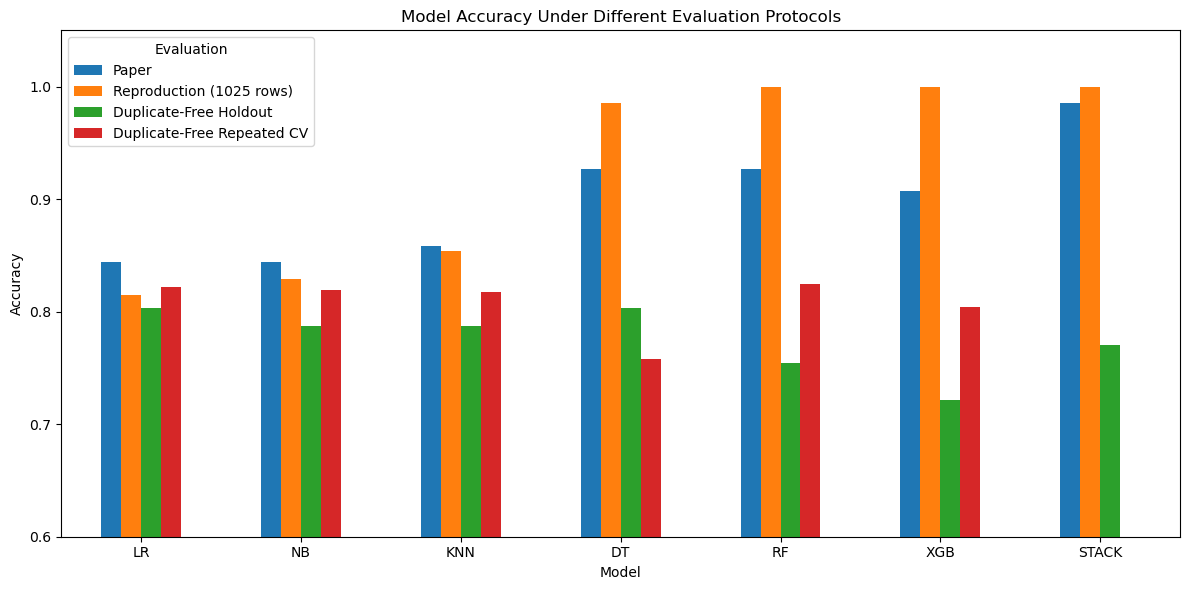

In [32]:
ax = accuracy_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Model Accuracy Under Different Evaluation Protocols"
)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.60, 1.05)

plt.xticks(rotation=0)
plt.legend(title="Evaluation")
plt.tight_layout()
plt.show()

## 7. Feature Selection Experiment

Mutual-information feature selection is evaluated with Random Forest using 5, 7, 9, 11, and all 13 predictors. Performance is assessed using the same repeated stratified cross-validation protocol.

This experiment tests whether reducing the feature set improves generalisation. The selected-feature scores are also inspected for interpretation; they are not treated as causal importance measures.


In [33]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

print("Feature selection tools imported successfully.")

Feature selection tools imported successfully.


In [34]:
feature_counts = [5, 7, 9, 11, 13]

feature_selection_results = []

for k in feature_counts:

    pipeline = Pipeline([
        (
            "feature_selection",
            SelectKBest(
                score_func=mutual_info_classif,
                k=k
            )
        ),
        (
            "classifier",
            RandomForestClassifier(
                random_state=RANDOM_STATE
            )
        )
    ])

    scores = cross_validate(
        pipeline,
        X_unique,
        y_unique,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    feature_selection_results.append({
        "Features": k,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "AUC Mean": scores["test_auc"].mean(),
        "AUC SD": scores["test_auc"].std()
    })

feature_selection_summary = pd.DataFrame(
    feature_selection_results
).set_index("Features")

display(feature_selection_summary.round(4))

,Accuracy Mean,Accuracy SD,Precision Mean,Recall Mean,F1 Mean,AUC Mean,AUC SD
Features,,,,,,,
5,0.7788,0.0515,0.7899,0.8123,0.7990,0.8561,0.0435
7,0.7947,0.0386,0.7992,0.8361,0.8152,0.8803,0.0332
9,0.8139,0.0421,0.8135,0.8573,0.8328,0.8922,0.0321
11,0.8225,0.0376,0.8250,0.8597,0.8399,0.8980,0.0290
13,0.8245,0.0405,0.8246,0.8639,0.8423,0.9018,0.0333


In [35]:
best_k = feature_selection_summary[
    "AUC Mean"
].idxmax()

best_row = feature_selection_summary.loc[best_k]

print(f"Best number of features based on mean AUC: {best_k}")

print("\nPerformance:")
print(
    f"Accuracy: "
    f"{best_row['Accuracy Mean']:.4f} "
    f"± {best_row['Accuracy SD']:.4f}"
)

print(
    f"F1:       "
    f"{best_row['F1 Mean']:.4f}"
)

print(
    f"AUC:      "
    f"{best_row['AUC Mean']:.4f} "
    f"± {best_row['AUC SD']:.4f}"
)

Best number of features based on mean AUC: 13

Performance:
Accuracy: 0.8245 ± 0.0405
F1:       0.8423
AUC:      0.9018 ± 0.0333


In [36]:
feature_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=best_k
)

feature_selector.fit(
    X_unique,
    y_unique
)

selected_mask = feature_selector.get_support()

selected_features = X_unique.columns[
    selected_mask
].tolist()

feature_scores = pd.DataFrame({
    "Feature": X_unique.columns,
    "Mutual Information":
        feature_selector.scores_,
    "Selected":
        selected_mask
}).sort_values(
    "Mutual Information",
    ascending=False
)

print(f"Selected features ({best_k}):")
print(selected_features)

print("\nFeature scores:")
display(feature_scores.round(4))

Selected features (13):
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Feature scores:


,Feature,Mutual Information,Selected
12,thal,0.1764,True
8,exang,0.1159,True
9,oldpeak,0.1100,True
2,cp,0.1096,True
10,slope,0.0859,True
11,ca,0.0789,True
7,thalach,0.0650,True
4,chol,0.0528,True
1,sex,0.0513,True
3,trestbps,0.0000,True


## 8. Random Forest Hyperparameter Optimisation

RandomizedSearchCV is used to explore Random Forest configurations using AUC as the optimisation metric. The search investigates the number of trees, tree depth, minimum split and leaf sizes, feature sampling, and class weighting.

The initial optimisation is exploratory. Its performance is compared with the duplicate-free Random Forest baseline before a nested cross-validation procedure is used for the final assessment.


In [37]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    (
        "classifier",
        RandomForestClassifier(
            random_state=RANDOM_STATE
        )
    )
])

rf_param_distributions = {
    "classifier__n_estimators": [
        100, 200, 300, 500
    ],
    "classifier__max_depth": [
        None, 3, 5, 7, 10
    ],
    "classifier__min_samples_split": [
        2, 4, 6, 10
    ],
    "classifier__min_samples_leaf": [
        1, 2, 3, 4
    ],
    "classifier__max_features": [
        "sqrt", "log2", None
    ],
    "classifier__class_weight": [
        None, "balanced"
    ]
}

inner_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=RANDOM_STATE
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=40,
    scoring="roc_auc",
    cv=inner_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

print("Random Forest hyperparameter search configured.")
print("Candidate configurations: 40")
print("Validation: 5 folds x 2 repetitions")
print("Optimisation metric: AUC")

Random Forest hyperparameter search configured.
Candidate configurations: 40
Validation: 5 folds x 2 repetitions
Optimisation metric: AUC


In [38]:
rf_search.fit(
    X_unique,
    y_unique
)

print("Hyperparameter optimisation completed.")

print("\nBest cross-validation AUC:")
print(round(rf_search.best_score_, 4))

print("\nBest parameters:")
for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

Hyperparameter optimisation completed.

Best cross-validation AUC:
0.9154

Best parameters:
classifier__n_estimators: 300
classifier__min_samples_split: 4
classifier__min_samples_leaf: 3
classifier__max_features: sqrt
classifier__max_depth: 3
classifier__class_weight: balanced


In [39]:
search_results = pd.DataFrame(
    rf_search.cv_results_
)

top_configs = (
    search_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

display(top_configs.round(4))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
15,1,0.9154,0.0205,0.9557,"{'classifier__n_estimators': 300, 'classifier_..."
37,2,0.9147,0.0218,0.9839,"{'classifier__n_estimators': 500, 'classifier_..."
39,3,0.9144,0.0211,0.9534,"{'classifier__n_estimators': 100, 'classifier_..."
28,4,0.9141,0.0222,0.9553,"{'classifier__n_estimators': 100, 'classifier_..."
36,4,0.9141,0.0222,0.9553,"{'classifier__n_estimators': 100, 'classifier_..."
20,6,0.9138,0.0201,0.9845,"{'classifier__n_estimators': 200, 'classifier_..."
27,7,0.9137,0.0228,0.9905,"{'classifier__n_estimators': 500, 'classifier_..."
19,8,0.9137,0.0201,0.9782,"{'classifier__n_estimators': 200, 'classifier_..."
17,9,0.9135,0.0227,0.9920,"{'classifier__n_estimators': 500, 'classifier_..."
1,10,0.9133,0.0241,0.9973,"{'classifier__n_estimators': 200, 'classifier_..."


In [40]:
best_rf = RandomForestClassifier(
    n_estimators=
        rf_search.best_params_[
            "classifier__n_estimators"
        ],

    max_depth=
        rf_search.best_params_[
            "classifier__max_depth"
        ],

    min_samples_split=
        rf_search.best_params_[
            "classifier__min_samples_split"
        ],

    min_samples_leaf=
        rf_search.best_params_[
            "classifier__min_samples_leaf"
        ],

    max_features=
        rf_search.best_params_[
            "classifier__max_features"
        ],

    class_weight=
        rf_search.best_params_[
            "classifier__class_weight"
        ],

    random_state=RANDOM_STATE
)

optimised_scores = cross_validate(
    best_rf,
    X_unique,
    y_unique,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

optimised_rf_results = pd.Series({
    "Accuracy Mean":
        optimised_scores["test_accuracy"].mean(),

    "Accuracy SD":
        optimised_scores["test_accuracy"].std(),

    "Precision Mean":
        optimised_scores["test_precision"].mean(),

    "Recall Mean":
        optimised_scores["test_recall"].mean(),

    "F1 Mean":
        optimised_scores["test_f1"].mean(),

    "AUC Mean":
        optimised_scores["test_auc"].mean(),

    "AUC SD":
        optimised_scores["test_auc"].std()
})

display(
    optimised_rf_results
    .to_frame("Optimised RF")
    .round(4)
)

,Optimised RF
Accuracy Mean,0.8318
Accuracy SD,0.0362
Precision Mean,0.8290
Recall Mean,0.8732
F1 Mean,0.8492
AUC Mean,0.9124
AUC SD,0.0312


In [41]:
rf_improvement = pd.DataFrame({
    "Baseline RF": {
        "Accuracy":
            cv_summary.loc["RF", "Accuracy Mean"],

        "Precision":
            cv_summary.loc["RF", "Precision Mean"],

        "Recall":
            cv_summary.loc["RF", "Recall Mean"],

        "F1":
            cv_summary.loc["RF", "F1 Mean"],

        "AUC":
            cv_summary.loc["RF", "AUC Mean"]
    },

    "Optimised RF": {
        "Accuracy":
            optimised_rf_results["Accuracy Mean"],

        "Precision":
            optimised_rf_results["Precision Mean"],

        "Recall":
            optimised_rf_results["Recall Mean"],

        "F1":
            optimised_rf_results["F1 Mean"],

        "AUC":
            optimised_rf_results["AUC Mean"]
    }
}).T

rf_improvement.loc[
    "Improvement"
] = (
    rf_improvement.loc["Optimised RF"]
    - rf_improvement.loc["Baseline RF"]
)

display(rf_improvement.round(4))

,Accuracy,Precision,Recall,F1,AUC
Baseline RF,0.8245,0.8246,0.8639,0.8423,0.9018
Optimised RF,0.8318,0.8290,0.8732,0.8492,0.9124
Improvement,0.0073,0.0044,0.0093,0.0069,0.0106


## 9. Final Evaluation Using Nested Cross-Validation

Nested cross-validation separates hyperparameter selection from final performance estimation. The outer 5-fold stratified split provides unseen evaluation folds, while a 3-fold stratified inner loop performs Random Forest hyperparameter optimisation using AUC.

This is the final evaluation protocol for the proposed duplicate-aware method.


In [42]:
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

inner_cv_nested = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

nested_results = []
nested_best_params = []

print("Nested CV configured:")
print("Outer CV: 5 folds")
print("Inner CV: 3 folds")
print("Random search: 20 configurations per outer fold")

Nested CV configured:
Outer CV: 5 folds
Inner CV: 3 folds
Random search: 20 configurations per outer fold


In [43]:
for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X_unique, y_unique),
    start=1
):

    X_train_outer = X_unique.iloc[train_idx]
    X_test_outer = X_unique.iloc[test_idx]

    y_train_outer = y_unique.iloc[train_idx]
    y_test_outer = y_unique.iloc[test_idx]

    rf_nested = RandomForestClassifier(
        random_state=RANDOM_STATE
    )

    search = RandomizedSearchCV(
        estimator=rf_nested,
        param_distributions={
            "n_estimators": [100, 200, 300, 500],
            "max_depth": [None, 3, 5, 7, 10],
            "min_samples_split": [2, 4, 6, 10],
            "min_samples_leaf": [1, 2, 3, 4],
            "max_features": ["sqrt", "log2", None],
            "class_weight": [None, "balanced"]
        },
        n_iter=20,
        scoring="roc_auc",
        cv=inner_cv_nested,
        random_state=RANDOM_STATE + fold,
        n_jobs=-1,
        refit=True
    )

    search.fit(
        X_train_outer,
        y_train_outer
    )

    best_model = search.best_estimator_

    y_pred = best_model.predict(
        X_test_outer
    )

    y_prob = best_model.predict_proba(
        X_test_outer
    )[:, 1]

    fold_result = {
        "Fold": fold,
        "Accuracy": accuracy_score(
            y_test_outer, y_pred
        ),
        "Precision": precision_score(
            y_test_outer, y_pred
        ),
        "Recall": recall_score(
            y_test_outer, y_pred
        ),
        "F1": f1_score(
            y_test_outer, y_pred
        ),
        "AUC": roc_auc_score(
            y_test_outer, y_prob
        )
    }

    nested_results.append(fold_result)

    nested_best_params.append({
        "Fold": fold,
        "Best Inner AUC":
            search.best_score_,
        **search.best_params_
    })

    print(
        f"Fold {fold} completed - "
        f"AUC: {fold_result['AUC']:.4f}"
    )

print("\nNested CV completed.")

Fold 1 completed - AUC: 0.8874
Fold 2 completed - AUC: 0.9340
Fold 3 completed - AUC: 0.9163
Fold 4 completed - AUC: 0.9248
Fold 5 completed - AUC: 0.9102

Nested CV completed.


In [44]:
nested_results_df = pd.DataFrame(
    nested_results
)

display(
    nested_results_df.round(4)
)

nested_summary = pd.DataFrame({
    "Mean": nested_results_df[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC"
        ]
    ].mean(),

    "SD": nested_results_df[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC"
        ]
    ].std()
})

print("\nFinal Nested CV Performance:")
display(nested_summary.round(4))

,Fold,Accuracy,Precision,Recall,F1,AUC
0,1,0.7705,0.8519,0.6970,0.7667,0.8874
1,2,0.8033,0.7442,0.9697,0.8421,0.9340
2,3,0.8167,0.8000,0.8750,0.8358,0.9163
3,4,0.9000,0.8857,0.9394,0.9118,0.9248
4,5,0.8000,0.8182,0.8182,0.8182,0.9102



Final Nested CV Performance:


,Mean,SD
Accuracy,0.8181,0.0488
Precision,0.8200,0.0536
Recall,0.8598,0.1083
F1,0.8349,0.0522
AUC,0.9145,0.0176


In [45]:
nested_params_df = pd.DataFrame(
    nested_best_params
)

display(nested_params_df.round(4))

,Fold,Best Inner AUC,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,class_weight
0,1,0.9066,300,10,3,sqrt,NaN,balanced
1,2,0.9078,200,6,2,log2,3.0,None
2,3,0.9146,100,10,2,log2,3.0,None
3,4,0.9000,300,4,3,log2,10.0,balanced
4,5,0.8897,200,10,4,log2,5.0,balanced


## 10. Final Experimental Comparison

The principal experimental stages are compared using Accuracy, Precision, Recall, F1-score, and AUC. The final visualisation contrasts the published stacking result, the conventional reproduction, the duplicate-free Random Forest baseline, and the proposed nested-cross-validation Random Forest.


In [46]:
final_comparison = pd.DataFrame({
    "Approach": [
        "Paper - Stacking",
        "Our Reproduction - Stacking",
        "Duplicate-Free RF Baseline",
        "Proposed Method - Nested CV RF"
    ],

    "Accuracy": [
        0.9853,
        stack_results.loc["STACK", "Accuracy"],
        cv_summary.loc["RF", "Accuracy Mean"],
        nested_summary.loc["Accuracy", "Mean"]
    ],

    "Precision": [
        1.0000,
        stack_results.loc["STACK", "Precision"],
        cv_summary.loc["RF", "Precision Mean"],
        nested_summary.loc["Precision", "Mean"]
    ],

    "Recall": [
        0.9727,
        stack_results.loc["STACK", "Recall"],
        cv_summary.loc["RF", "Recall Mean"],
        nested_summary.loc["Recall", "Mean"]
    ],

    "F1": [
        0.9861,
        stack_results.loc["STACK", "F1"],
        cv_summary.loc["RF", "F1 Mean"],
        nested_summary.loc["F1", "Mean"]
    ],

    "AUC": [
        0.9880,
        stack_results.loc["STACK", "AUC"],
        cv_summary.loc["RF", "AUC Mean"],
        nested_summary.loc["AUC", "Mean"]
    ]
})

display(final_comparison.round(4))

,Approach,Accuracy,Precision,Recall,F1,AUC
0,Paper - Stacking,0.9853,1.0000,0.9727,0.9861,0.9880
1,Our Reproduction - Stacking,1.0000,1.0000,1.0000,1.0000,1.0000
2,Duplicate-Free RF Baseline,0.8245,0.8246,0.8639,0.8423,0.9018
3,Proposed Method - Nested CV RF,0.8181,0.8200,0.8598,0.8349,0.9145


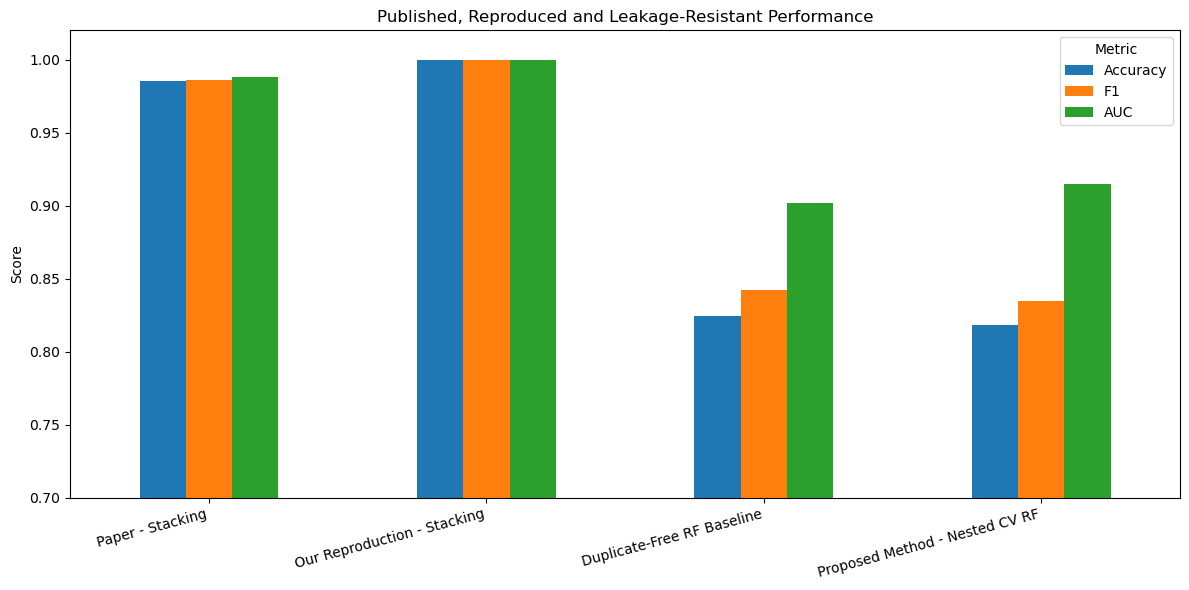

In [47]:
plot_data = final_comparison.set_index(
    "Approach"
)[["Accuracy", "F1", "AUC"]]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Published, Reproduced and Leakage-Resistant Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("")

ax.set_ylim(0.70, 1.02)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.legend(
    title="Metric"
)

plt.tight_layout()
plt.show()

In [48]:
performance_effect = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "F1",
        "AUC"
    ],

    "Reproduction": [
        stack_results.loc["STACK", "Accuracy"],
        stack_results.loc["STACK", "F1"],
        stack_results.loc["STACK", "AUC"]
    ],

    "Proposed Nested CV": [
        nested_summary.loc["Accuracy", "Mean"],
        nested_summary.loc["F1", "Mean"],
        nested_summary.loc["AUC", "Mean"]
    ]
})

performance_effect["Absolute Difference"] = (
    performance_effect["Reproduction"]
    - performance_effect["Proposed Nested CV"]
)

performance_effect["Difference (percentage points)"] = (
    performance_effect["Absolute Difference"] * 100
)

display(
    performance_effect.round(4)
)

,Metric,Reproduction,Proposed Nested CV,Absolute Difference,Difference (percentage points)
0,Accuracy,1.0,0.8181,0.1819,18.1913
1,F1,1.0,0.8349,0.1651,16.5092
2,AUC,1.0,0.9145,0.0855,8.5452


## 11. Save Reproducible Results

The principal tables used in the report are exported to the project `results` directory so that the reported values can be traced directly to notebook outputs.


In [49]:
from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_comparison.to_csv(
    results_dir / "final_comparison.csv",
    index=False
)

nested_results_df.to_csv(
    results_dir / "nested_cv_folds.csv",
    index=False
)

nested_summary.to_csv(
    results_dir / "nested_cv_summary.csv"
)

feature_selection_summary.to_csv(
    results_dir / "feature_selection_results.csv"
)

rf_improvement.to_csv(
    results_dir / "rf_optimisation_comparison.csv"
)

print("Results saved successfully:")
for file in results_dir.iterdir():
    print("-", file.name)

Results saved successfully:
- feature_selection_results.csv
- final_comparison.csv
- nested_cv_folds.csv
- nested_cv_summary.csv
- rf_optimisation_comparison.csv


## Conclusion

The conventional reproduction produced very high performance, including perfect scores for the reproduced stacking ensemble. The data-quality audit showed that the 1,025-row dataset contains 723 repeated observations and only 302 unique records, while 98.54% of the conventional test set had an identical record in the training data.

After duplicate removal, performance estimates became substantially more conservative. The final nested-cross-validation Random Forest achieved an average Accuracy of approximately 0.818, F1-score of 0.835, and AUC of 0.915. The main contribution of the proposed workflow is therefore not a universally higher classification score, but a more rigorous separation of data-quality assessment, model optimisation, and final performance estimation.

The small number of unique observations remains an important limitation, and external validation would be required before drawing conclusions about clinical deployment.